# M14.5 — Eventos reales con M14.5a (Σ aprendida)

Evaluación **descriptiva** (n = 9, una semilla, sin tests, sin selección) de `M14_5a_4a_G3T_fullcov_s123` en los 9 eventos
GWTC-3-confident de M13.13, con exactamente el mismo procesado.

- **Entradas.** X de eventos de `scripts/m14/export_real_events_X.py` (celdas 2, 4, 6, 8, 10 y 12 de `M13_13_real_events`
  ejecutadas desde el notebook, con el gate de reproducción de M13.7); μ, σ, Σ y embedding de `scripts/m14/predict_events_npz.py`
  (VM), con comprobación de reproducción de `preds_val_G3T` en las primeras filas de val.
- **Intervalos principales: configuración de M14.7** (1 bin, simétrica, score r/σ en las tres etiquetas), con sus calibradores de
  cal guardados, sin reajustar: μ ± q_label·σ, σ = √diag Σ.
- **Referencia descriptiva:** el Mondrian heredado de M11 (celda 6 de M13.7 reajustada con cal de M14.5a, como en
  `M14_5_evaluation`; conservative): v1 y v2 de M14.3, en una tabla aparte. Su modelo de dificultad da la distancia kNN.
- **Elipsoides S.** s = rᵀ Σ⁻¹ r con los radios de cal de M14.5 (3D 6,0720; 2D 4,3986), adoptados por la enmienda 2.
- **LVK.** Muestras `C01:Mixed` (variante `mixed_cosmo`), sistema del detector, como en M13.7 y M13.13. Cal, val y test se usan
  solo para reconstruir lo ya fijado (calibradores, radios) y como referencia de la distancia kNN; nada se ajusta ni se elige
  con eventos reales.

## 1. Parámetros y CONFIG

In [1]:
MODEL_TAG = "M14_5a_4a_G3T_fullcov_s123"
EXPECTED_CHECKPOINT_NAME = f"{MODEL_TAG}_final.pt"
CHECKPOINT_REL = f"M13_3/{MODEL_TAG}_final.pt"     # relative to <data_root>/models/checkpoints/ (hashed, not loaded)
TRAIN_CFG_REL = "configs/experiments/m14/train_m14_5a_4aG3T_fullcov_s123.json"
VARIANT = dict(template_bank=False)               # read by the reused load_pred of M14.5
G3T_MARK = "m13_13_g3t"
MEMMAP_NAMES = {"cal": "fp16_memmap_heldout", "val": "fp16_memmap", "test": "fp16_memmap_heldout"}
G3_CFG_REL = "configs/experiments/m13/train_m13_4a_G3aug_s123.json"   # G3 HDF5: y of train (support P2)

# Files of this evaluation, in <data_root>/results/M13_3/M14_5/real_events/ (fill in after the export and the VM run).
EVENTS_X_NAME = "events_X_20261112T161429Z.npz"
EVENTS_PRED_NAME = "events_pred_M14_5a_20261112T163505Z.npz"
VAL_CHECK_MIN_ROWS = 64

# Executed runs that are read here.
M14_5_RUN_STAMP = "20261112T142455Z"              # M14.5 run with amendment 2
M14_5_SUMMARY_NAME = f"M14_5_summary_{MODEL_TAG}_20261112T142537Z.json"
M13_13_REAL_STAMP = "20261110T130749Z"            # M13.13 real events (events, LVK medians, processing)
M13_13_MONDRIAN_RUN = "run_20261110T234654Z"      # M13.13 amendment 6 (4a-G3T): comparison table
M13_13_TAG = "M13_13_4a_G3T_s123"
M13_7_RUN = "run_20261102T164134Z"

# M14.7: configuration chosen on val and confirmed on test (main intervals), relative to <data_root>/results/.
M14_7_RUN_REL = "M13_3/M14_7/M14_5a_4a_G3T_fullcov_s123/run_20261112T161005Z"
M14_7_STAMP = "20261112T161005Z"
M14_7_EXPECTED_CONFIG = dict(taxonomy_mode="none", interval_mode="symmetric", n_bins=1, n_neighbors=None, score="r/sigma")
M14_7_VAL_TOL = 1e-4          # |coverage - M14.7| and |mean width / M14.7 - 1| on val

PRIMARY_POLICY = "conservative"
LEVEL = 0.90
DIMS = {"3D": (0, 1, 2), "2D": (0, 1)}            # 2D = (chirp_mass, total_mass)
RADIUS_EXPECTED = {"3D": 6.0720, "2D": 4.3986}    # cal radii of M14.5 (4 decimals)
# The cal refit of M13.7 cell 6 jitters bin edges by 1e-10 (no seed): the val table of M14.5 is reproduced
# within these tolerances, not bitwise.
MONDRIAN_VAL_COV_ATOL, MONDRIAN_VAL_WIDTH_RTOL = 1e-4, 1e-4
LVK_MEDIAN_RTOL = 1e-12

OUT_OF_SUPPORT = {"GW200202_154313": "fuera de soporte (𝓜 < P2 de train)"}
SUPPORT_QUANTILE = 0.02                           # P2 of train chirp_mass (detector frame)
KNN_FAR_QUANTILE = 0.99                           # as M13.13 amendment 6

CONFIG = dict(
    labels={"chirp_mass": r"$\mathcal{M}$", "total_mass": r"$M_{\mathrm{tot}}$", "chi_eff": r"$\chi_{\mathrm{eff}}$"},
    units={"chirp_mass": r"$M_\odot$, detector", "total_mass": r"$M_\odot$, detector", "chi_eff": "adim."},
    lvk=dict(name="LVK C01:Mixed", color="0.55", contour_color="0.15", scatter_size=2, scatter_alpha=0.12),
    ellipse=dict(name="elipse S 2D (radio de cal)", color="#2a6fb0"),
    main=dict(name="M14.7 (1 bin, simétrica, r/σ)", color="#c4512b"),
    mu=dict(name="μ M14.5a", color="k"),
    lvk_median=dict(name="mediana LVK", color="0.15"),
    max_scatter=4000, kde_max=5000, kde_grid=150, seed=145101,
    grid_figsize=(15, 14), label_figsize=(11, 5.5), dpi=150,
    fig_names=dict(grid=f"{MODEL_TAG}_real_events_mc_mtot_grid",
                   per_label=f"{MODEL_TAG}_real_events_m14_7_vs_lvk90_{{label}}"),
)

## 2. Imports, rutas y código reutilizado

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from copy import copy
from dataclasses import replace
import sys, ast, json, pickle, hashlib, re   # re: pe_file (M13.7 cell 27)
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.stats import gaussian_kde
from IPython.display import display

root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if root is None:
    raise RuntimeError("Abrir desde cbc_pe")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.paths import resolve_project_root, resolve_data_root, resolve_processed_artifact
from src.conformal.selected_calibrators import fit_selected_calibrators   # used by the reused M13.7 cell 6
from src.conformal.pipeline import apply_mondrian, evaluate_mondrian, MondrianPrediction
from src.conformal.binning import BinGrouper                     # used by the reused fit_v2
from src.conformal.calibration import ConformalIntervalCalibrator  # used by the reused fit_v2

PROJECT_ROOT = resolve_project_root()
def read_json(path):
    return json.loads(Path(path).read_text())
def require(condition, message):
    if not condition:
        raise ValueError(message)
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()
def x_sha256(X):
    """Same definition as scripts/m14/export_real_events_X.py and predict_events_npz.py."""
    return hashlib.sha256(np.ascontiguousarray(X, dtype=np.float32).tobytes()).hexdigest()

LABELS = ["chirp_mass", "total_mass", "chi_eff"]
POLICIES = ["conservative", "efficient"]   # read by the reused M13.7 cell 6

train_cfg = read_json(PROJECT_ROOT / TRAIN_CFG_REL)
require(train_cfg["outputs"]["checkpoint_tag"] == MODEL_TAG, "train config checkpoint_tag != MODEL_TAG")
require(train_cfg["model"].get("heteroscedastic") is True and train_cfg["model"].get("covariance") == "full",
        "train config is not a full-covariance heteroscedastic model")
DATA_ROOT = resolve_data_root(config_data_root=train_cfg["data_root"])
DATASET_ID_G3T = train_cfg["dataset"]["dataset_id"]
SPLIT_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3T,
                                        file_name=train_cfg["dataset"]["split_file"])
LABEL_STATS_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3T,
                                              file_name=train_cfg["dataset"]["label_stats_file"])
g3_ds = read_json(PROJECT_ROOT / G3_CFG_REL)["dataset"]
DATASET_ID_G3 = g3_ds["dataset_id"]
require(DATASET_ID_G3T == f"{DATASET_ID_G3}/{G3T_MARK}", "G3 / G3T dataset ids")
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3, file_name=g3_ds["dataset_file"])
MEMMAP_DIRS = {s: DATA_ROOT / "processed" / DATASET_ID_G3T / name for s, name in MEMMAP_NAMES.items()}

RESULTS = DATA_ROOT / "results"
M13_DIR = RESULTS / "M13_3"
PRED_PATHS = {s: M13_DIR / f"{MODEL_TAG}/preds_{s}_G3T/{s}_predictions_embeddings.npz" for s in ("cal", "val", "test")}
CHECKPOINT = DATA_ROOT / "models/checkpoints" / CHECKPOINT_REL
EV_DIR = M13_DIR / "M14_5/real_events"
EVENTS_X = EV_DIR / EVENTS_X_NAME
EVENTS_PRED = EV_DIR / EVENTS_PRED_NAME
M14_5_SUMMARY = M13_DIR / "M14_5" / MODEL_TAG / M14_5_SUMMARY_NAME
M13_13_REAL_JSON = M13_DIR / "M13_13/real_events" / f"M13_13_real_events_{M13_13_REAL_STAMP}.json"
M13_13_MONDRIAN_JSON = (M13_DIR / "M13_13/mondrian_G3T" / M13_13_MONDRIAN_RUN
                        / f"M13_13_mondrian_G3T_{M13_13_MONDRIAN_RUN.removeprefix('run_')}.json")
M13_7_DIR = M13_DIR / "M13_4b_G3aug_s123" / "M13_7_pipeline_provisional" / M13_7_RUN
M13_7_SUMMARY = M13_7_DIR / f"M13_7_summary_{M13_7_RUN.removeprefix('run_')}.json"
M14_7_DIR = RESULTS / M14_7_RUN_REL
M14_7_BUNDLE = M14_7_DIR / f"M14_7_mondrian_calibrators_cal_only_{M14_7_STAMP}.pkl"
M14_7_SELECTION = M14_7_DIR / f"M14_7_selection_val_{M14_7_STAMP}.json"
M14_7_SUMMARY = M14_7_DIR / f"M14_7_summary_{M14_7_STAMP}.json"
M11_RESULTS = RESULTS / "M11_final_G1_500k"
M11_SELECTION = M11_RESULTS / "mondrian_m11_selected_from_val.csv"
M11_BUNDLE_MANIFEST = M11_RESULTS / "mondrian_m11_selected_calibrators_frozen_provenance.json"

# LVK posterior samples: same choice as M13.7 section 6b and M13.13 (checked against its JSON in section 3).
PE_DIR = DATA_ROOT / "external/gwtc3_pe"
PE_VARIANT = "mixed_cosmo"
PE_GROUP = "C01:Mixed"
PE_LEVEL = 0.90
PE_Q = [(1 - PE_LEVEL) / 2, 1 - (1 - PE_LEVEL) / 2]

NOTEBOOKS = {"M13_7": PROJECT_ROOT / "notebooks/m13/M13_7_pipeline_provisional_4b.ipynb",
             "M14_3": PROJECT_ROOT / "notebooks/m14/M14_3_mondrian_v2.ipynb",
             "M14_4": PROJECT_ROOT / "notebooks/m14/M14_4_residual_correlation.ipynb",
             "M14_5": PROJECT_ROOT / "notebooks/m14/M14_5_evaluation.ipynb"}

RUN_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUN_DIR = EV_DIR / f"run_{RUN_STAMP}"         # v1 bundle written by the reused M13.7 cell 6 (cal-only refit)
FIG_DIR = EV_DIR / "figures"
JSON_PATH = EV_DIR / f"M14_5_real_events_{MODEL_TAG}_{RUN_STAMP}.json"
require(not RUN_DIR.exists() and not JSON_PATH.exists(), "Output of this stamp already exists")

inputs_to_check = [("events X", EVENTS_X), ("events predictions (VM)", EVENTS_PRED),
    *[(f"pred {s}", p) for s, p in PRED_PATHS.items()], ("checkpoint (hashed only)", CHECKPOINT),
    *[(f"row_ids {s}", MEMMAP_DIRS[s] / f"row_ids_{s}.npy") for s in MEMMAP_DIRS],
    ("split", SPLIT_PATH), ("label stats (train only)", LABEL_STATS_PATH), ("G3 HDF5 (train y)", G3_H5),
    ("M14.5 summary", M14_5_SUMMARY), ("M14.7 bundle", M14_7_BUNDLE), ("M14.7 selection (val)", M14_7_SELECTION),
    ("M14.7 summary", M14_7_SUMMARY), ("M13.13 real-event JSON", M13_13_REAL_JSON),
    ("M13.13 amendment 6 JSON", M13_13_MONDRIAN_JSON), ("M13.7 summary", M13_7_SUMMARY),
    ("M11 selection (val)", M11_SELECTION), ("M11 bundle manifest", M11_BUNDLE_MANIFEST),
    *[(f"{k} notebook", p) for k, p in NOTEBOOKS.items()]]
path_audit = pd.DataFrame([dict(role=r, path=str(p), exists=p.is_file()) for r, p in inputs_to_check])
with pd.option_context("display.max_colwidth", None):
    display(path_audit)
require(path_audit.exists.all(), "Missing required inputs; inspect path table")

# Reuse of closed notebooks without copying them (same mechanism as M14.3, M14.4 and M14.5, cell 4).
NOTEBOOK_CELLS = {k: read_json(p)["cells"] for k, p in NOTEBOOKS.items()}
reused_sources = {}

def reuse_cell(source, cell_index, names=None):
    """Run a code cell of a closed notebook here, or define only its functions `names`."""
    cell = NOTEBOOK_CELLS[source][cell_index]
    require(cell["cell_type"] == "code", f"{source} cell {cell_index} is not code")
    text = "".join(cell["source"])
    tree = ast.parse(text)
    if names is not None:
        tree.body = [n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name in names]
        require({n.name for n in tree.body} == set(names), f"{source} cell {cell_index} does not define {names}")
    reused_sources[f"{source}/cell_{cell_index}"] = dict(names=names, sha256=hashlib.sha256(text.encode()).hexdigest())
    exec(compile(tree, f"{source}_cell_{cell_index}", "exec"), globals())

reuse_cell("M13_7", 11, ["read_hdf5_dataset_preserve_order"])
reuse_cell("M13_7", 27, ["pe_file", "read_pe_samples"])
reuse_cell("M14_3", 12, ["fit_v2"])
reuse_cell("M14_3", 14, ["apply_v2", "per_row"])
reuse_cell("M14_3", 34, ["to_json", "records", "input_entry"])
reuse_cell("M14_4", 18, ["v1_on_split"])
reuse_cell("M14_5", 6, ["load_pred"])
reuse_cell("M14_5", 14, ["mahalanobis"])
print(json.dumps(reused_sources, indent=2))
print("Model:", MODEL_TAG, "| run stamp:", RUN_STAMP)

,role,path,exists
0,events X,/data/vserrano/cbc_pe_data/results/M13_3/M14_5/real_events/events_X_20261112T161429Z.npz,True
1,events predictions (VM),/data/vserrano/cbc_pe_data/results/M13_3/M14_5/real_events/events_pred_M14_5a_20261112T163505Z.npz,True
2,pred cal,/data/vserrano/cbc_pe_data/results/M13_3/M14_5a_4a_G3T_fullcov_s123/preds_cal_G3T/cal_predictions_embeddings.npz,True
3,pred val,/data/vserrano/cbc_pe_data/results/M13_3/M14_5a_4a_G3T_fullcov_s123/preds_val_G3T/val_predictions_embeddings.npz,True
4,pred test,/data/vserrano/cbc_pe_data/results/M13_3/M14_5a_4a_G3T_fullcov_s123/preds_test_G3T/test_predictions_embeddings.npz,True
5,checkpoint (hashed only),/data/vserrano/cbc_pe_data/models/checkpoints/M13_3/M14_5a_4a_G3T_fullcov_s123_final.pt,True
6,row_ids cal,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/row_ids_cal.npy,True
7,row_ids val,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap/row_ids_val.npy,True
8,row_ids test,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/row_ids_test.npy,True
9,split,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/../M11_final_G1_500k_splits_train400000_val40000_cal30000_test30000_seed123.npz,True


{
  "M13_7/cell_11": {
    "names": [
      "read_hdf5_dataset_preserve_order"
    ],
    "sha256": "f099a982debdc92ba1beff856b10043efd228a7fd7f2ee23d2499566f4e25a0c"
  },
  "M13_7/cell_27": {
    "names": [
      "pe_file",
      "read_pe_samples"
    ],
    "sha256": "8ea96871ad792f87789e855d6ed233da61733eefc55a6681faefe16b0fd3f8b0"
  },
  "M14_3/cell_12": {
    "names": [
      "fit_v2"
    ],
    "sha256": "fd500ea8577bd520c3f11b32ef9c4491e8c10edbc72bbc0c14cf42c651719b7d"
  },
  "M14_3/cell_14": {
    "names": [
      "apply_v2",
      "per_row"
    ],
    "sha256": "8bba8df74aa45892444429a72a19a109e94f849dc4059f6f0f1a5bb49d562b68"
  },
  "M14_3/cell_34": {
    "names": [
      "to_json",
      "records",
      "input_entry"
    ],
    "sha256": "d21af75086d1b12331dc24d1a10896677c2ea7e8909e037917f1bf465087d512"
  },
  "M14_4/cell_18": {
    "names": [
      "v1_on_split"
    ],
    "sha256": "a687ac315e07543b0c05ce6b6f7c26bfdae49bb6fc09d65892814ff4cd36cb6d"
  },
  "M14_5/cell_6": {

## 3. Gates (si falla alguno, el notebook se para)

- **Procedencia de cal/val/test:** `load_pred` de M14.5 (split único, orden de etiquetas, escalador train-only, checkpoint,
  cabeza completa, memmap, split); idx = pertenencia al split y = row_ids del memmap; sha256 de los npz = los del resumen de M14.5.
- **Eventos:** los 9 de M13.13 (mismo cohorte, mismo contrato de procesado, mismas celdas de M13.7); sha256 de X = el guardado en el
  export = el usado por la VM; el gate de reproducción de M13.7 pasó en el export.
- **Predicciones de eventos:** checkpoint con el sha256 del fichero local, escalador train-only, mismos eventos en el mismo orden,
  comprobación de val superada (al menos `VAL_CHECK_MIN_ROWS` filas), Σ simétrica y definida positiva, σ = √diag Σ.
- **Radios S** recalculados en cal = los de M14.5 (redondeo a 4 decimales = 6,0720 / 4,3986); la enmienda 2 adopta la Σ aprendida.

In [3]:
CHECKS = []
def check(ok, name):
    require(bool(ok), "Check failed: " + name)
    CHECKS.append(name)

with np.load(LABEL_STATS_PATH) as stats:
    stats_mean, stats_std = (stats[k].astype(np.float32) for k in ("y_mean", "y_std"))
y_mean, y_std = stats_mean.astype(float), stats_std.astype(float)
with np.load(SPLIT_PATH, allow_pickle=True) as z:
    split_indices = {s: np.asarray(z[f"{s}_idx"], dtype=np.int64) for s in ("train", "val", "cal", "test")}

# cal / val / test of M14.5a, with the gates of M14.5 (cell 6).
SPLITS, NPZ_PROVENANCE = {}, {}
for s, path in PRED_PATHS.items():
    SPLITS[s], NPZ_PROVENANCE[f"model/{s}"] = load_pred(path, s, EXPECTED_CHECKPOINT_NAME, "full")
EMB_DIM = SPLITS["cal"]["emb"].shape[1]
for s, d in SPLITS.items():
    n = len(split_indices[s])
    check(d["idx"].shape == (n,) and np.array_equal(np.sort(d["idx"]), np.sort(split_indices[s])), f"{s}: idx = split membership")
    row_ids = np.load(MEMMAP_DIRS[s] / f"row_ids_{s}.npy").astype(np.int64)
    check(np.array_equal(np.sort(d["idx"]), np.sort(row_ids)), f"{s}: idx = row_ids of {MEMMAP_DIRS[s].name}")
    for name, shape in (("pred", (n, 3)), ("sigma", (n, 3)), ("emb", (n, EMB_DIM)), ("cov", (n, 3, 3))):
        check(d[name].shape == shape and np.isfinite(d[name]).all(), f"{s}: {name} shape and finite")

M14_5_SUM = read_json(M14_5_SUMMARY)
check(M14_5_SUM["model_tag"] == MODEL_TAG and M14_5_SUM["run_stamp_utc"] == M14_5_RUN_STAMP, "M14.5 summary: model and run")
for s in ("cal", "val"):
    check(M14_5_SUM["inputs"]["pred"][s]["sha256"] == file_sha256(PRED_PATHS[s]), f"{s}: npz = the one of M14.5")
check(M14_5_SUM["amendment_2"]["test"]["inputs"]["model"]["sha256"] == file_sha256(PRED_PATHS["test"]), "test: npz = M14.5 amendment 2")
A2_DECISION = M14_5_SUM["amendment_2"]["decision"]
check(A2_DECISION["adopt_learned_sigma"] is True, "amendment 2 adopts the learned Sigma")

# Events X (export) and the M13.13 real-event run.
m13_real = read_json(M13_13_REAL_JSON)
with np.load(EVENTS_X, allow_pickle=False) as z:
    X_EV = np.asarray(z["X"], dtype=np.float32)
    EV_NAMES = z["event_names"].astype(str).tolist()
    EV_GPS = np.asarray(z["gps"], dtype=float)
    EV_X_SHA = str(z["x_sha256"])
    EV_META = json.loads(str(z["metadata_json"]))
check(x_sha256(X_EV) == EV_X_SHA == EV_META["x_sha256"], "events X: sha256 = the one stored by the export")
check(len(EV_NAMES) == 9 and set(EV_NAMES) == set(m13_real["events"]), "events = the 9 of M13.13")
check(set(OUT_OF_SUPPORT) <= set(EV_NAMES), "out-of-support event among the 9")
check(EV_META["m13_13_real_events_json"]["sha256"] == file_sha256(M13_13_REAL_JSON), "export read the same M13.13 JSON")
check(EV_META["cohort"]["sha256"] == m13_real["provenance"]["cohort_sha256"], "cohort = M13.13")
check(EV_META["processing"] == m13_real["processing"], "processing contract = M13.13")
check(EV_META["reused_m13_7_cells"] == m13_real["provenance"]["reused_m13_7_cells"], "M13.7 processing cells = M13.13")
g = EV_META["gate_m13_7"]
check(g["passed"] and g["max_abs_delta"] <= g["tolerance"], "M13.7 reproduction gate passed in the export")
check(reused_sources["M13_7/cell_27"]["sha256"] == m13_real["provenance"]["reused_m13_7_cells"]["cell_27"]["sha256"],
      "LVK reader (M13.7 cell 27) = M13.13")
lvk_m13 = m13_real["lvk_posterior"]
check((lvk_m13["variant"], lvk_m13["group"], lvk_m13["level"]) == (PE_VARIANT, PE_GROUP, PE_LEVEL), "LVK samples = M13.13")

# Event predictions of the VM.
with np.load(EVENTS_PRED, allow_pickle=False) as z:
    EV = {k: np.asarray(z[k], dtype=float) for k in ("pred", "sigma", "cov", "emb")}
    PRED_META = dict(checkpoint_file=str(z["checkpoint_file"]), checkpoint_sha256=str(z["checkpoint_sha256"]),
                     checkpoint_tag=str(z["checkpoint_tag"]), input_sha256=str(z["input_sha256"]),
                     x_sha256=str(z["x_sha256"]), torch_version=str(z["torch_version"]), device=str(z["device"]),
                     created_utc=str(z["created_utc"]), model_config=json.loads(str(z["model_config_json"])),
                     val_check=json.loads(str(z["val_check_json"])))
    pred_events = z["event_names"].astype(str).tolist()
    pred_labels = z["label_names"].astype(str).tolist()
    pred_y_mean, pred_y_std = np.asarray(z["y_mean"]), np.asarray(z["y_std"])
CHECKPOINT_SHA256 = file_sha256(CHECKPOINT)
check(Path(PRED_META["checkpoint_file"]).name == EXPECTED_CHECKPOINT_NAME and PRED_META["checkpoint_tag"] == MODEL_TAG,
      "event predictions: checkpoint")
check(PRED_META["checkpoint_sha256"] == CHECKPOINT_SHA256, "event predictions: checkpoint sha256 = local file")
check(PRED_META["input_sha256"] == file_sha256(EVENTS_X) and PRED_META["x_sha256"] == EV_X_SHA, "event predictions: same X")
check(pred_events == EV_NAMES and pred_labels == LABELS, "event predictions: events and label order")
check(np.array_equal(pred_y_mean, stats_mean) and np.array_equal(pred_y_std, stats_std), "event predictions: train-only scaler")
mk = PRED_META["model_config"]["model_kwargs"]
check(mk.get("heteroscedastic") and mk.get("covariance") == "full", "event predictions: full-covariance head")
vc = PRED_META["val_check"]
check(vc["passed"] and vc["n"] >= VAL_CHECK_MIN_ROWS, f"VM val check passed on >= {VAL_CHECK_MIN_ROWS} rows")
for name, shape in (("pred", (9, 3)), ("sigma", (9, 3)), ("cov", (9, 3, 3)), ("emb", (9, EMB_DIM))):
    check(EV[name].shape == shape and np.isfinite(EV[name]).all(), f"events: {name} shape and finite")
check(np.abs(EV["cov"] - EV["cov"].transpose(0, 2, 1)).max() <= 1e-6, "events: cov symmetric")
check(np.all(np.linalg.eigvalsh(EV["cov"]).min(1) > 0), "events: cov positive definite")
check(np.abs(EV["sigma"] - np.sqrt(np.diagonal(EV["cov"], axis1=1, axis2=2))).max() <= 1e-6, "events: sigma = sqrt(diag cov)")
display(pd.DataFrame([dict(n=vc["n"], max_abs_dmu=vc["max_abs_dmu"], max_abs_dcov=vc["max_abs_dcov"], tol=vc["tol"],
                           torch=PRED_META["torch_version"], device=PRED_META["device"])]))

# S radii: k-th s of cal, k = ceil((n_cal + 1) 0.9), as M14.5 (cells 14 and 18).
n_cal = len(SPLITS["cal"]["idx"])
K_RANK = int(np.ceil((n_cal + 1) * LEVEL))
check(K_RANK == M14_5_SUM["c3"]["k_rank"], "k rank = M14.5")
RADIUS_S = {dim: float(np.sort(mahalanobis(SPLITS["cal"], cols))[K_RANK - 1]) for dim, cols in DIMS.items()}
for dim in DIMS:
    check(np.isclose(RADIUS_S[dim], M14_5_SUM["c3"]["radius_S"][dim], rtol=1e-12, atol=0), f"radius {dim} = M14.5")
    check(round(RADIUS_S[dim], 4) == RADIUS_EXPECTED[dim], f"radius {dim} = {RADIUS_EXPECTED[dim]}")
print("Radios S:", RADIUS_S)
print("GATES superados:", len(CHECKS), "comprobaciones")

,n,max_abs_dmu,max_abs_dcov,tol,torch,device
0,64,0.0,0.0,0.00001,1.9.1+cu111,cuda


Radios S: {'3D': 6.071971042063609, '2D': 4.398567801182407}
GATES superados: 88 comprobaciones


## 4. Mondrian heredado de M11 (v1 / v2): referencia descriptiva y modelo de dificultad

Reconstruido con cal como en `M14_5_evaluation` (celda 24): la celda 6 de M13.7 sin cambios ajusta los seis sistemas solo con cal
de M14.5a y escribe su bundle en `RUN_DIR`; v2 con `fit_v2` de M14.3 (σ = √diag Σ de cal). No da los intervalos principales (son
los de M14.7, sección 4b); se usa en la tabla de referencia de la sección 5 y, por su modelo de dificultad, en la distancia kNN de
la sección 6. Gate de reconstrucción: en val, v1 (`v1_on_split`) y v2 (`apply_v2`) reproducen la tabla de cobertura y anchura
media de M14.5 (grupo "all").

En los eventos no hay y, así que no se puede llamar a `v1_on_split` / `apply_v2` (evalúan cobertura). `v1_bounds` y `v2_bounds`
hacen las mismas llamadas sin la evaluación; se comprueba que en val dan exactamente los mismos límites y bins.

In [4]:
RUN_DIR.mkdir(parents=True, exist_ok=False)
OUTPUT_DIR = RUN_DIR                        # M13.7 cell 6 writes its bundle here
TAG = MODEL_TAG                             # recorded by M13.7 cell 6 in the bundle metadata
pred_cal, y_cal, emb_cal = (SPLITS["cal"][k] for k in ("pred", "y", "emb"))
PREDICTIONS_PATH = PRED_PATHS["cal"]        # the only predictions used for the fit
DATASET_ID = DATASET_ID_G3T
check_helper = check                        # M13.7 cell 6 binds `check` to a DataFrame
reuse_cell("M13_7", 6)
m13_7_selection_check, check = check, check_helper

m13_7_summary = read_json(M13_7_SUMMARY)
check(m13_7_summary["mondrian"]["hyperparameters"] == HP, "Mondrian hyperparameters = M13.7")
ours_systems = selected[["final_policy", "label", "taxonomy_mode", "interval_mode", "n_bins"]].to_dict("records")
key = lambda r: (r["final_policy"], r["label"])
check(sorted(m13_7_summary["mondrian"]["systems"], key=key) ==
      sorted([{k: (int(v) if k == "n_bins" else v) for k, v in r.items()} for r in ours_systems], key=key),
      "Mondrian systems (taxonomy, interval mode, n_bins) = M13.7")

SIGMA_CAL = SPLITS["cal"]["sigma"]          # sqrt(diag Sigma); global read by the reused fit_v2
V1_SYSTEMS = {l: calibrators[(PRIMARY_POLICY, l)] for l in LABELS}
V2_SYSTEMS = {l: fit_v2(V1_SYSTEMS[l]) for l in LABELS}
for l in LABELS:
    s1, s2 = V1_SYSTEMS[l], V2_SYSTEMS[l]
    check(s2.fitted.bin_indices_cal is s1.fitted.bin_indices_cal, f"{l}: v2 shares the cal bin assignment of v1")

# Reconstruction gate on val against the M14.5 table.
V = SPLITS["val"]
n_val = len(V["idx"])
V1_VAL = {l: v1_on_split(V1_SYSTEMS[l], V) for l in LABELS}
V2_VAL = {l: apply_v2(V2_SYSTEMS[l], V1_VAL[l], V) for l in LABELS}
ref_table = pd.DataFrame(M14_5_SUM["descriptive"]["mondrian"]["table"])
ref_table = ref_table[ref_table.group == "all"].set_index(["version", "label"])
recon_rows = []
for v, res in (("v1", V1_VAL), ("v2", V2_VAL)):
    for l in LABELS:
        cov_rows, w = per_row(res[l], V)
        ref = ref_table.loc[(v, l)]
        recon_rows.append(dict(version=v, label=l, coverage=float(cov_rows.mean()), coverage_m14_5=float(ref.coverage),
                               mean_width_phys=float(w.mean()), mean_width_phys_m14_5=float(ref.mean_width_phys)))
RECON = pd.DataFrame(recon_rows)
RECON["abs_dcoverage"] = (RECON.coverage - RECON.coverage_m14_5).abs()
RECON["rel_dwidth"] = (RECON.mean_width_phys / RECON.mean_width_phys_m14_5 - 1).abs()
with pd.option_context("display.float_format", "{:.6g}".format):
    display(RECON)
check((RECON.abs_dcoverage <= MONDRIAN_VAL_COV_ATOL).all() and (RECON.rel_dwidth <= MONDRIAN_VAL_WIDTH_RTOL).all(),
      "v1/v2 on val reproduce the M14.5 table")

def v1_bounds(system, d):
    """v1 limits and bins: the calls of v1_on_split (M14.4 cell 18) without the coverage evaluation."""
    j = system.label_index
    fitted = replace(system.fitted, difficulty_model=copy(system.fitted.difficulty_model))
    p = apply_mondrian(fitted, pred_target=d["pred"],
                       target_embedding=d["emb"] if system.taxonomy_mode == "difficulty" else None)
    return p.lower[:, j], p.upper[:, j], p.bin_indices[:, j].astype(int)

def v2_bounds(system2, bins, d):
    """v2 limits: the formula of apply_v2 (M14.3 cell 14), offsets of v2 rescaled by sigma per row."""
    j = system2.label_index
    off = system2.fitted.calibrator.intervals_[j]
    return d["pred"][:, j] + off[bins, 0] * d["sigma"][:, j], d["pred"][:, j] + off[bins, 1] * d["sigma"][:, j]

for l in LABELS:
    lo1, hi1, b = v1_bounds(V1_SYSTEMS[l], V)
    lo2, hi2 = v2_bounds(V2_SYSTEMS[l], b, V)
    p1, p2 = V1_VAL[l]["prediction"], V2_VAL[l]["prediction"]
    check(np.array_equal(b, p1.bin_indices[:, 0].astype(int)), f"{l}: v1_bounds bins = v1_on_split on val")
    check(np.array_equal(lo1, p1.lower[:, 0]) and np.array_equal(hi1, p1.upper[:, 0]), f"{l}: v1_bounds = v1_on_split on val")
    check(np.array_equal(lo2, p2.lower[:, 0]) and np.array_equal(hi2, p2.upper[:, 0]), f"{l}: v2_bounds = apply_v2 on val")
print("Reconstrucción de Mondrian v1/v2 comprobada en val")

,final_policy,label,label_index,selection_policy,taxonomy_mode,interval_mode,n_bins
0,conservative,chirp_mass,0,conservative_zero_under_bins_2sigma,difficulty,asymmetric,16
1,efficient,chirp_mass,0,efficient_local_validity_tolerant,difficulty,asymmetric,48
2,conservative,total_mass,1,conservative_zero_under_bins_2sigma,prediction,asymmetric,4
3,efficient,total_mass,1,efficient_local_validity_tolerant,prediction,asymmetric,4
4,conservative,chi_eff,2,conservative_zero_under_bins_2sigma,difficulty,symmetric,8
5,efficient,chi_eff,2,efficient_local_validity_tolerant,difficulty,symmetric,4


fit cal only conservative/chirp_mass: difficulty/asymmetric/16
fit cal only efficient/chirp_mass: difficulty/asymmetric/48
fit cal only conservative/total_mass: prediction/asymmetric/4
fit cal only efficient/total_mass: prediction/asymmetric/4
fit cal only conservative/chi_eff: difficulty/symmetric/8
fit cal only efficient/chi_eff: difficulty/symmetric/4
Bundle: /data/vserrano/cbc_pe_data/results/M13_3/M14_5/real_events/run_20261112T170136Z/mondrian_m13_7_4b_calibrators_cal_only.pkl 059c86c7ed08bdbcbda4dd5cb73f0458f34b3cb97a44884af0a10cf8b193b7da


,version,label,coverage,coverage_m14_5,mean_width_phys,mean_width_phys_m14_5,abs_dcoverage,rel_dwidth
0,v1,chirp_mass,0.90435,0.90435,14.6031,14.6031,0,0
1,v1,total_mass,0.90085,0.90085,27.4884,27.4884,0,0
2,v1,chi_eff,0.900225,0.900225,0.536969,0.536969,0,0
3,v2,chirp_mass,0.902925,0.902925,14.1177,14.1177,0,0
4,v2,total_mass,0.9008,0.9008,25.8351,25.8351,0,0
5,v2,chi_eff,0.898375,0.898375,0.518844,0.518844,0,0


Reconstrucción de Mondrian v1/v2 comprobada en val


## 4b. Intervalos principales: configuración de M14.7

Bundle de M14.7 (ajustado solo con cal y serializado antes de test), cargado sin reajustar. Configuración usada por etiqueta
(`to_use` del resumen, fuente "selected": 1 bin, simétrica, score r/σ). Intervalo: [μ + q_lo·σ, μ + q_hi·σ] con
`[q_lo, q_hi] = intervals_[label_index][0]` (simétrica: q_lo = −q_hi), σ = √diag Σ; es la aplicación de `apply_one_bin` de
M14.7 (celda 12) y la que describe el campo `application` del bundle. Gate: sha256 del bundle y del JSON de selección = los del
resumen; en val, cobertura y anchura media física = las de la configuración elegida en M14.7 (tolerancia `M14_7_VAL_TOL`).

In [5]:
M14_7_SUM = read_json(M14_7_SUMMARY)
M14_7_SEL = read_json(M14_7_SELECTION)
check(M14_7_SUM["model"] == MODEL_TAG and M14_7_SUM["run_stamp"] == M14_7_STAMP, "M14.7 summary: model and run")
M14_7_BUNDLE_SHA256 = file_sha256(M14_7_BUNDLE)
check(M14_7_SUM["bundle"]["sha256"] == M14_7_BUNDLE_SHA256 == M14_7_SEL["bundle"]["sha256"], "M14.7 bundle sha256 = summary")
check(M14_7_SUM["selection_json"]["sha256"] == file_sha256(M14_7_SELECTION), "M14.7 selection JSON sha256 = summary")
with M14_7_BUNDLE.open("rb") as f:
    m14_7_bundle = pickle.load(f)          # trusted own artifact (cal-only state)
bm = m14_7_bundle["metadata"]
check(bm["model"] == MODEL_TAG and bm["label_names"] == LABELS and bm["fit_split"] == "cal"
      and bm["calibration_space"] == "standardized", "M14.7 bundle metadata: model, labels, cal, standardized")
check(np.array_equal(np.asarray(bm["y_mean"]), y_mean) and np.array_equal(np.asarray(bm["y_std"]), y_std), "M14.7 bundle: train-only scaler")
check(bm["predictions_cal"]["sha256"] == file_sha256(PRED_PATHS["cal"]), "M14.7 bundle fitted on the same cal npz")

M14_7_Q, M14_7_CONFIG, M14_7_VAL = {}, {}, []
V = SPLITS["val"]
for j, l in enumerate(LABELS):
    use = M14_7_SUM["to_use"][l]
    cfg = use["config"]
    check(use["source"] == "selected", f"{l}: M14.7 uses its selected configuration")
    check(cfg == M14_7_SUM["selected"][l] == M14_7_SEL["selected"][l] == m14_7_bundle["selected"][l]["config"],
          f"{l}: same configuration in summary, selection JSON and bundle")
    check(cfg == dict(label=l, **M14_7_EXPECTED_CONFIG), f"{l}: configuration = 1 bin, symmetric, r/sigma")
    system = m14_7_bundle["selected"][l]["system"]
    check(system.label_index == j and system.n_bins == 1 and system.fitted.n_bins == 1, f"{l}: one-bin system, label index")
    off = np.asarray(system.fitted.calibrator.intervals_[j][0], dtype=float)     # [q_lo, q_hi], standardized r/sigma
    check(off.shape == (2,) and off[1] > 0 and np.isclose(off[0], -off[1], rtol=1e-12, atol=0), f"{l}: symmetric offsets")
    M14_7_Q[l], M14_7_CONFIG[l] = off, cfg
    # Val gate: same application as apply_one_bin (M14.7 cell 12), score r/sigma.
    lo, hi = V["pred"][:, j] + off[0] * V["sigma"][:, j], V["pred"][:, j] + off[1] * V["sigma"][:, j]
    cov_v = float(((lo <= V["y"][:, j]) & (V["y"][:, j] <= hi)).mean())
    w_v = float(((hi - lo) * y_std[j]).mean())
    ref = M14_7_SEL["selected_val"][l]
    check(ref["n_eval"] == len(V["idx"]), f"{l}: M14.7 val n = {len(V['idx'])}")
    M14_7_VAL.append(dict(label=l, q=float(off[1]), coverage=cov_v, coverage_m14_7=ref["coverage"],
                          mean_width_phys=w_v, mean_width_phys_m14_7=ref["mean_width_phys"]))
M14_7_VAL = pd.DataFrame(M14_7_VAL)
M14_7_VAL["abs_dcoverage"] = (M14_7_VAL.coverage - M14_7_VAL.coverage_m14_7).abs()
M14_7_VAL["rel_dwidth"] = (M14_7_VAL.mean_width_phys / M14_7_VAL.mean_width_phys_m14_7 - 1).abs()
with pd.option_context("display.float_format", "{:.6g}".format):
    display(M14_7_VAL)
check((M14_7_VAL.abs_dcoverage <= M14_7_VAL_TOL).all() and (M14_7_VAL.rel_dwidth <= M14_7_VAL_TOL).all(),
      "M14.7 configuration on val reproduces the M14.7 coverage and mean width")

def main_bounds(l, d):
    """Main interval (standardized): mu + [q_lo, q_hi] sigma with the stored M14.7 offsets."""
    j = LABELS.index(l)
    return d["pred"][:, j] + M14_7_Q[l][0] * d["sigma"][:, j], d["pred"][:, j] + M14_7_Q[l][1] * d["sigma"][:, j]

,label,q,coverage,coverage_m14_7,mean_width_phys,mean_width_phys_m14_7,abs_dcoverage,rel_dwidth
0,chirp_mass,1.6014,0.90225,0.90225,14.017,14.017,0,0
1,total_mass,1.61473,0.9012,0.9012,25.7334,25.7334,0,0
2,chi_eff,1.62528,0.8985,0.8985,0.518517,0.518517,0,0


## 5. Por evento: μ, σ, intervalos de M14.7, elipsoides S y comparación con LVK

Unidades físicas (sistema del detector para las masas). Intervalo principal = M14.7 (`main_*`). En S, s = rᵀ Σ⁻¹ r se calcula en
unidades estandarizadas (es la misma s que con Σ física y r físico). `mu_quantile_in_lvk` = fracción de muestras LVK ≤ μ.
`width_ratio_main_lvk90` = anchura del intervalo de M14.7 / anchura del 90 % central de LVK. `lvk_frac_in_S_2D` = fracción de
muestras LVK dentro de la elipse S 2D. El Mondrian heredado de M11 (v1, v2) va en una tabla aparte (`REFERENCE_M11`), solo
descriptiva.

In [6]:
EVD = dict(pred=EV["pred"], sigma=EV["sigma"], emb=EV["emb"])
MU_PHYS = EV["pred"] * y_std + y_mean
SIGMA_PHYS = EV["sigma"] * y_std
COV_PHYS = EV["cov"] * y_std[None, :, None] * y_std[None, None, :]
MAIN = {}
for j, l in enumerate(LABELS):
    lo, hi = main_bounds(l, EVD)
    MAIN[l] = dict(lower=lo * y_std[j] + y_mean[j], upper=hi * y_std[j] + y_mean[j])
# Inherited M11 Mondrian (reference only).
INTERVALS = {}
for l in LABELS:
    j = LABELS.index(l)
    lo1, hi1, b = v1_bounds(V1_SYSTEMS[l], EVD)
    lo2, hi2 = v2_bounds(V2_SYSTEMS[l], b, EVD)
    INTERVALS[l] = dict(bin=b, v1_lower=lo1 * y_std[j] + y_mean[j], v1_upper=hi1 * y_std[j] + y_mean[j],
                        v2_lower=lo2 * y_std[j] + y_mean[j], v2_upper=hi2 * y_std[j] + y_mean[j])

# LVK posterior samples, read and checked as in M13_13_real_events (cell 16).
pe_paths = {event: pe_file(event) for event in EV_NAMES}
require(all(p is not None for p in pe_paths.values()), f"Missing PE files: {pe_paths}")
manifest_files = {f["key"]: f for m in sorted(PE_DIR.glob("manifest_*.json")) for f in read_json(m)["files"]}
PE_SAMPLES, pe_info = {}, {}
for event, path in pe_paths.items():
    samples, info = read_pe_samples(path)
    entry = manifest_files.get(path.name)
    check(entry is not None and entry["size"] == info["size"], f"{path.name}: in the download manifests, same size")
    info["md5_zenodo"] = entry["md5"]
    PE_SAMPLES[event], pe_info[event] = samples, info

rows, ref_rows = [], []
for i, event in enumerate(EV_NAMES):
    s = PE_SAMPLES[event]
    for j, l in enumerate(LABELS):
        lo, hi = np.quantile(s[:, j], PE_Q)
        med = float(np.median(s[:, j]))
        rows.append(dict(event=event, label=l, mu=MU_PHYS[i, j], sigma=SIGMA_PHYS[i, j], q_m14_7=float(M14_7_Q[l][1]),
            main_lower=MAIN[l]["lower"][i], main_upper=MAIN[l]["upper"][i],
            lvk_pe_median=med, lvk_pe_lower90=float(lo), lvk_pe_upper90=float(hi), n_lvk_samples=len(s)))
        iv = INTERVALS[l]
        ref_rows.append(dict(event=event, label=l, mondrian_bin=int(iv["bin"][i]), taxonomy_mode=V1_SYSTEMS[l].taxonomy_mode,
            v2_lower=iv["v2_lower"][i], v2_upper=iv["v2_upper"][i], v1_lower=iv["v1_lower"][i], v1_upper=iv["v1_upper"][i],
            lvk_pe_median=med, lvk_pe_lower90=float(lo), lvk_pe_upper90=float(hi)))
PER_LABEL = pd.DataFrame(rows)
PER_LABEL["main_width"] = PER_LABEL.main_upper - PER_LABEL.main_lower
PER_LABEL["lvk_width90"] = PER_LABEL.lvk_pe_upper90 - PER_LABEL.lvk_pe_lower90
PER_LABEL["residual"] = PER_LABEL.mu - PER_LABEL.lvk_pe_median
PER_LABEL["lvk_median_inside_main"] = ((PER_LABEL.main_lower <= PER_LABEL.lvk_pe_median)
                                       & (PER_LABEL.lvk_pe_median <= PER_LABEL.main_upper))
PER_LABEL["mu_quantile_in_lvk"] = [float(np.mean(PE_SAMPLES[e][:, LABELS.index(l)] <= m))
                                   for e, l, m in zip(PER_LABEL.event, PER_LABEL.label, PER_LABEL.mu)]
PER_LABEL["width_ratio_main_lvk90"] = PER_LABEL.main_width / PER_LABEL.lvk_width90

REFERENCE_M11 = pd.DataFrame(ref_rows)
lvk_w = REFERENCE_M11.lvk_pe_upper90 - REFERENCE_M11.lvk_pe_lower90
for v in ("v1", "v2"):
    REFERENCE_M11[f"{v}_width"] = REFERENCE_M11[f"{v}_upper"] - REFERENCE_M11[f"{v}_lower"]
    REFERENCE_M11[f"lvk_median_inside_{v}"] = ((REFERENCE_M11[f"{v}_lower"] <= REFERENCE_M11.lvk_pe_median)
                                               & (REFERENCE_M11.lvk_pe_median <= REFERENCE_M11[f"{v}_upper"]))
    REFERENCE_M11[f"width_ratio_{v}_lvk90"] = REFERENCE_M11[f"{v}_width"] / lvk_w

# The LVK reference must be the one of M13.13.
ref = pd.DataFrame(m13_real["per_event"])
ref = ref[ref.model == M13_13_TAG].set_index(["event", "label"])
ours = PER_LABEL.set_index(["event", "label"])
check(set(ref.index) == set(ours.index), "events/labels = M13.13 JSON")
for c in ("lvk_pe_median", "lvk_pe_lower90", "lvk_pe_upper90"):
    check(np.allclose(ours[c], ref.loc[ours.index, c], rtol=LVK_MEDIAN_RTOL, atol=0), f"LVK {c} = M13.13 JSON")

# Ellipsoids S (standardized units; same s as mahalanobis of M14.5).
ell_rows = []
for i, event in enumerate(EV_NAMES):
    s = PE_SAMPLES[event]
    med_std = (np.median(s, axis=0) - y_mean) / y_std
    one = dict(y=med_std[None], pred=EV["pred"][i:i + 1], cov=EV["cov"][i:i + 1])
    s3, s2 = (float(mahalanobis(one, DIMS[d])[0]) for d in ("3D", "2D"))
    n_s = len(s)
    allsamp = dict(y=(s - y_mean) / y_std, pred=np.repeat(EV["pred"][i:i + 1], n_s, 0), cov=np.repeat(EV["cov"][i:i + 1], n_s, 0))
    s2_samples = mahalanobis(allsamp, DIMS["2D"])
    ell_rows.append(dict(event=event, s_lvk_median_3D=s3, lvk_median_in_S_3D=s3 <= RADIUS_S["3D"],
                         s_lvk_median_2D=s2, lvk_median_in_S_2D=s2 <= RADIUS_S["2D"],
                         lvk_frac_in_S_2D=float(np.mean(s2_samples <= RADIUS_S["2D"])), n_lvk_samples=n_s))
ELLIPSE = pd.DataFrame(ell_rows)

event_order = PER_LABEL[PER_LABEL.label == "chirp_mass"].sort_values("lvk_pe_median").event.tolist()
def sort_events(df):
    df = df.assign(_e=df.event.map(event_order.index))
    keys = ["_l", "_e"] if "label" in df else ["_e"]
    if "label" in df:
        df["_l"] = df.label.map(LABELS.index)
    return df.sort_values(keys).drop(columns=keys).reset_index(drop=True)
PER_LABEL, REFERENCE_M11, ELLIPSE = sort_events(PER_LABEL), sort_events(REFERENCE_M11), sort_events(ELLIPSE)
with pd.option_context("display.max_rows", 100, "display.max_columns", 30, "display.float_format", "{:.4g}".format):
    display(PER_LABEL[["event", "label", "mu", "sigma", "main_lower", "main_upper", "main_width", "lvk_pe_median",
                       "lvk_pe_lower90", "lvk_pe_upper90", "lvk_median_inside_main", "mu_quantile_in_lvk",
                       "width_ratio_main_lvk90"]])
    display(ELLIPSE)

# Counts over the 9 events (descriptive, n = 9).
COUNTS = (PER_LABEL.groupby("label", sort=False)
          .agg(lvk_median_inside_main=("lvk_median_inside_main", "sum"),
               median_width_ratio_main_lvk90=("width_ratio_main_lvk90", "median"), n=("event", "size")).reset_index())
COUNTS_S = dict(lvk_median_in_S_3D=int(ELLIPSE.lvk_median_in_S_3D.sum()), lvk_median_in_S_2D=int(ELLIPSE.lvk_median_in_S_2D.sum()),
                median_lvk_frac_in_S_2D=float(ELLIPSE.lvk_frac_in_S_2D.median()), n=len(ELLIPSE))
display(COUNTS)
print(COUNTS_S)

# Reference only: inherited M11 Mondrian (v1, v2 conservative).
print("Referencia descriptiva: Mondrian heredado de M11 (conservative)")
with pd.option_context("display.max_rows", 100, "display.max_columns", 30, "display.float_format", "{:.4g}".format):
    display(REFERENCE_M11[["event", "label", "mondrian_bin", "taxonomy_mode", "v2_lower", "v2_upper", "v2_width",
                           "v1_lower", "v1_upper", "v1_width", "lvk_median_inside_v2", "lvk_median_inside_v1",
                           "width_ratio_v2_lvk90", "width_ratio_v1_lvk90"]])
COUNTS_REF_M11 = (REFERENCE_M11.groupby("label", sort=False)
                  .agg(lvk_median_inside_v2=("lvk_median_inside_v2", "sum"), lvk_median_inside_v1=("lvk_median_inside_v1", "sum"),
                       median_width_ratio_v2_lvk90=("width_ratio_v2_lvk90", "median"), n=("event", "size")).reset_index())
display(COUNTS_REF_M11)

,event,label,mu,sigma,main_lower,main_upper,main_width,lvk_pe_median,lvk_pe_lower90,lvk_pe_upper90,lvk_median_inside_main,mu_quantile_in_lvk,width_ratio_main_lvk90
0,GW200202_154313,chirp_mass,9.342,1.46,7.004,11.68,4.675,8.148,8.101,8.197,True,1,48.5
1,GW200316_215756,chirp_mass,10.34,1.31,8.244,12.44,4.197,10.68,10.56,10.79,True,6.189e-05,18.2
2,GW191215_223052,chirp_mass,22.22,2.309,18.52,25.92,7.396,24.87,23.42,26.34,True,0.003152,2.534
3,GW200129_065458,chirp_mass,30.65,1.955,27.52,33.79,6.262,32.06,29.43,33.84,True,0.147,1.418
4,GW200311_115853,chirp_mass,32.12,2.239,28.53,35.7,7.172,32.67,29.92,35.34,True,0.3605,1.322
5,GW200208_130117,chirp_mass,34.01,6.466,23.65,44.36,20.71,38.82,34.05,44.02,True,0.04906,2.077
6,GW200224_222234,chirp_mass,39.78,2.837,35.24,44.33,9.088,40.93,37.11,44.44,True,0.3024,1.239
7,GW200219_094415,chirp_mass,36.47,6.951,25.34,47.6,22.26,43.74,37.53,50.07,True,0.03393,1.775
8,GW191230_180458,chirp_mass,53.86,7.887,41.23,66.49,25.26,62.06,51.87,71.02,True,0.08696,1.319
9,GW200202_154313,total_mass,25.98,7.257,14.26,37.7,23.44,19.01,18.67,21.01,True,0.9961,10.04


,event,s_lvk_median_3D,lvk_median_in_S_3D,s_lvk_median_2D,lvk_median_in_S_2D,lvk_frac_in_S_2D,n_lvk_samples
0,GW200202_154313,1.087,True,0.9264,True,0.9989,43480
1,GW200316_215756,0.9241,True,0.7506,True,0.9955,129267
2,GW191215_223052,1.708,True,1.347,True,0.9245,8884
3,GW200129_065458,0.896,True,0.589,True,0.9062,1993
4,GW200311_115853,0.3849,True,0.09475,True,0.9577,20276
5,GW200208_130117,0.6081,True,0.5854,True,0.9858,14981
6,GW200224_222234,0.3732,True,0.338,True,0.9545,11459
7,GW200219_094415,1.618,True,1.149,True,0.8987,9991
8,GW191230_180458,1.652,True,1.578,True,0.7619,7026


,label,lvk_median_inside_main,median_width_ratio_main_lvk90,n
0,chirp_mass,9,1.774518,9
1,total_mass,9,1.502724,9
2,chi_eff,9,1.619656,9


{'lvk_median_in_S_3D': 9, 'lvk_median_in_S_2D': 9, 'median_lvk_frac_in_S_2D': 0.9545335544113797, 'n': 9}
Referencia descriptiva: Mondrian heredado de M11 (conservative)


,event,label,mondrian_bin,taxonomy_mode,v2_lower,v2_upper,v2_width,v1_lower,v1_upper,v1_width,lvk_median_inside_v2,lvk_median_inside_v1,width_ratio_v2_lvk90,width_ratio_v1_lvk90
0,GW200202_154313,chirp_mass,3,difficulty,6.856,11.84,4.983,5.911,12.83,6.924,True,True,51.7,71.84
1,GW200316_215756,chirp_mass,4,difficulty,8.21,12.44,4.228,6.104,14.74,8.633,True,True,18.33,37.43
2,GW191215_223052,chirp_mass,8,difficulty,18.24,25.7,7.458,14.5,29.2,14.7,True,True,2.556,5.037
3,GW200129_065458,chirp_mass,4,difficulty,27.47,33.78,6.309,26.42,35.05,8.633,True,True,1.428,1.954
4,GW200311_115853,chirp_mass,4,difficulty,28.47,35.7,7.225,27.88,36.51,8.633,True,True,1.332,1.591
5,GW200208_130117,chirp_mass,11,difficulty,22.61,43.55,20.95,23.87,42.79,18.92,True,True,2.101,1.897
6,GW200224_222234,chirp_mass,7,difficulty,34.94,44.01,9.076,32.78,46.28,13.5,True,True,1.238,1.841
7,GW200219_094415,chirp_mass,14,difficulty,24.53,46.89,22.36,22.3,49.09,26.79,True,True,1.782,2.135
8,GW191230_180458,chirp_mass,11,difficulty,39.95,65.5,25.55,43.73,62.65,18.92,True,True,1.335,0.9881
9,GW200202_154313,total_mass,0,prediction,15.48,38.87,23.39,17.69,35.12,17.43,True,True,10.02,7.465


,label,lvk_median_inside_v2,lvk_median_inside_v1,median_width_ratio_v2_lvk90,n
0,chirp_mass,9,9,1.78236,9
1,total_mass,9,9,1.51570,9
2,chi_eff,9,9,1.56716,9


## 6. Distancia kNN a cal en el embedding y soporte en 𝓜

Como (d′) de M13.13 enmienda 6: distancia media del embedding a sus 5 vecinos de cal con el mismo `NearestNeighbors` del modelo
de dificultad del Mondrian heredado de M11 (reajustado con cal de M14.5a, sección 4), situada en la distribución de esa distancia en test de M14.5a (solo
referencia descriptiva). Marcas: "lejos de cal" por encima del P99 de test, "fuera del rango de test" por encima del máximo.

Soporte: P2 de 𝓜 en train (y del HDF5 de G3, sistema del detector). Se marca `OUT_OF_SUPPORT` y se informa si la mediana LVK y μ
quedan por debajo de ese P2.

In [7]:
difficulty_systems = {key_: s for key_, s in calibrators.items() if s.taxonomy_mode == "difficulty"}
check(difficulty_systems, "difficulty systems present")
E = EV["emb"]
emb_test = SPLITS["test"]["emb"]
knn = {}
for key_, s in sorted(difficulty_systems.items()):
    dm = s.fitted.difficulty_model
    check(not dm.standardize_embeddings and dm.n_neighbors == HP["n_neighbors"], f"{key_}: difficulty model as M13.13")
    knn[key_] = (dm.nn_model_.kneighbors(E, n_neighbors=dm.n_neighbors)[0].mean(1),
                 dm.nn_model_.kneighbors(emb_test, n_neighbors=dm.n_neighbors)[0].mean(1))
ref_key = sorted(knn)[0]
for key_, (d_e, d_t) in knn.items():   # every system is fitted on the same cal embeddings
    check(np.allclose(d_e, knn[ref_key][0], rtol=1e-12) and np.allclose(d_t, knn[ref_key][1], rtol=1e-12),
          f"{key_}: kNN distances equal across difficulty systems")
d_event, d_test = knn[ref_key]
d_test_q99, d_test_max = float(np.quantile(d_test, KNN_FAR_QUANTILE)), float(d_test.max())
KNN = pd.DataFrame(dict(event=EV_NAMES, knn_mean_distance=d_event, test_percentile=[float(np.mean(d_test <= d)) for d in d_event]))
KNN["knn_flag"] = np.where(d_event > d_test_max, "fuera del rango de test", np.where(d_event > d_test_q99, "lejos de cal", ""))
KNN_TEST = dict(n=int(len(d_test)), median=float(np.median(d_test)), q99=d_test_q99, max=d_test_max,
                k=int(HP["n_neighbors"]), source_system=list(ref_key))

with h5py.File(G3_H5, "r") as h:
    check(h.attrs.get("experiment_id") == DATASET_ID_G3 and str(h.attrs.get("labels")).split(",") == LABELS, "G3 HDF5 identity")
    y_train_chirp = read_hdf5_dataset_preserve_order(h, "y", np.sort(split_indices["train"]))[:, 0].astype(float)
P2_CHIRP_TRAIN = float(np.quantile(y_train_chirp, SUPPORT_QUANTILE))
mc = PER_LABEL[PER_LABEL.label == "chirp_mass"].set_index("event")
KNN["lvk_chirp_median"] = KNN.event.map(mc.lvk_pe_median)
KNN["mu_chirp"] = KNN.event.map(mc.mu)
KNN["lvk_median_below_p2_train"] = KNN.lvk_chirp_median < P2_CHIRP_TRAIN
KNN["mu_below_p2_train"] = KNN.mu_chirp < P2_CHIRP_TRAIN
KNN["support"] = KNN.event.map(OUT_OF_SUPPORT).fillna("")
KNN = KNN.assign(_e=KNN.event.map(event_order.index)).sort_values("_e").drop(columns="_e").reset_index(drop=True)
SUPPORT_PREMISE = bool(KNN.loc[KNN.support != "", "lvk_median_below_p2_train"].all())
display(KNN)
print(KNN_TEST)
print(f"P2 train chirp_mass = {P2_CHIRP_TRAIN:.4f}; OUT_OF_SUPPORT con mediana LVK < P2: {SUPPORT_PREMISE}")

,event,knn_mean_distance,test_percentile,knn_flag,lvk_chirp_median,mu_chirp,lvk_median_below_p2_train,mu_below_p2_train,support
0,GW200202_154313,0.950910,0.996333,lejos de cal,8.148216,9.341811,True,True,fuera de soporte (𝓜 < P2 de train)
1,GW200316_215756,0.520848,0.890500,,10.676260,10.342722,False,True,
2,GW191215_223052,0.636011,0.961433,,24.867089,22.221578,False,False,
3,GW200129_065458,0.224475,0.067533,,32.063561,30.654912,False,False,
4,GW200311_115853,0.244277,0.124500,,32.669543,32.118262,False,False,
5,GW200208_130117,0.389149,0.659700,,38.816372,34.006960,False,False,
6,GW200224_222234,0.234850,0.094100,,40.926222,39.784452,False,False,
7,GW200219_094415,0.469889,0.826667,,43.736712,36.472363,False,False,
8,GW191230_180458,0.612165,0.951700,,62.064472,53.858893,False,False,


{'n': 30000, 'median': 0.3385199461774431, 'q99': 0.8052589500459363, 'max': 1.9322240235023778, 'k': 5, 'source_system': ['conservative', 'chi_eff']}
P2 train chirp_mass = 10.4104; OUT_OF_SUPPORT con mediana LVK < P2: True


## 7. Comparación con M13.13 (4a-G3T, enmienda 6)

Leída del resumen guardado de la enmienda 6 (`real_events.per_event`, política conservative): intervalo Mondrian v1 de 4a-G3T,
predicción puntual y su distancia kNN. Frente a M14.5a: μ, intervalo de M14.7 y distancia kNN. `abs_residual_change` = |residuo nuevo| −
|residuo antiguo| respecto a la mediana LVK (negativo = más cerca). Descriptivo.

In [8]:
m13_mond = read_json(M13_13_MONDRIAN_JSON)
check(m13_mond["experiment"] == "M13.13 enmienda 6" and m13_mond["model"] == M13_13_TAG, "M13.13 amendment 6 JSON: model")
check(m13_mond["real_events"]["lvk_posterior"]["variant"] == PE_VARIANT and m13_mond["real_events"]["lvk_posterior"]["group"] == PE_GROUP,
      "M13.13 amendment 6: same LVK samples")
old = pd.DataFrame(m13_mond["real_events"]["per_event"])
old = old[old.policy == PRIMARY_POLICY]
check(len(old) == 27 and set(old.event) == set(EV_NAMES), "M13.13 amendment 6: 9 events x 3 labels")
old = old.rename(columns={"prediction": "pred_m13_13", "lower": "lower_m13_13", "upper": "upper_m13_13", "width": "width_m13_13",
                          "lvk_median_inside_mondrian": "lvk_median_inside_m13_13", "test_percentile": "knn_test_percentile_m13_13"})
COMPARE = PER_LABEL.merge(old[["event", "label", "lvk_pe_median", "pred_m13_13", "lower_m13_13", "upper_m13_13", "width_m13_13",
                               "lvk_median_inside_m13_13", "knn_test_percentile_m13_13"]],
                          on=["event", "label"], suffixes=("", "_m13_13"), validate="one_to_one")
check(np.allclose(COMPARE.lvk_pe_median, COMPARE.lvk_pe_median_m13_13, rtol=LVK_MEDIAN_RTOL, atol=0), "LVK medians = amendment 6 JSON")
COMPARE = COMPARE.merge(KNN[["event", "test_percentile"]].rename(columns={"test_percentile": "knn_test_percentile"}), on="event")
COMPARE["residual_m13_13"] = COMPARE.pred_m13_13 - COMPARE.lvk_pe_median
COMPARE["abs_residual_change"] = COMPARE.residual.abs() - COMPARE.residual_m13_13.abs()
COMPARE["width_ratio_main_vs_m13_13"] = COMPARE.main_width / COMPARE.width_m13_13
COMPARE["support"] = COMPARE.event.map(OUT_OF_SUPPORT).fillna("")
COMPARE_COLS = ["event", "label", "lvk_pe_median", "pred_m13_13", "mu", "residual_m13_13", "residual", "abs_residual_change",
                "lower_m13_13", "upper_m13_13", "main_lower", "main_upper", "width_m13_13", "main_width", "width_ratio_main_vs_m13_13",
                "lvk_median_inside_m13_13", "lvk_median_inside_main", "knn_test_percentile_m13_13", "knn_test_percentile", "support"]
COMPARE = COMPARE[COMPARE_COLS]
with pd.option_context("display.max_rows", 100, "display.max_columns", 30, "display.float_format", "{:.4g}".format):
    display(COMPARE)
COMPARE_SUMMARY = (COMPARE.groupby("label", sort=False)
                   .agg(inside_m13_13=("lvk_median_inside_m13_13", "sum"), inside_main=("lvk_median_inside_main", "sum"),
                        closer=("abs_residual_change", lambda x: int((x < 0).sum())),
                        median_abs_residual_m13_13=("residual_m13_13", lambda x: float(x.abs().median())),
                        median_abs_residual=("residual", lambda x: float(x.abs().median())),
                        median_width_ratio_main_vs_m13_13=("width_ratio_main_vs_m13_13", "median")).reset_index())
display(COMPARE_SUMMARY)

,event,label,lvk_pe_median,pred_m13_13,mu,residual_m13_13,residual,abs_residual_change,lower_m13_13,upper_m13_13,main_lower,main_upper,width_m13_13,main_width,width_ratio_main_vs_m13_13,lvk_median_inside_m13_13,lvk_median_inside_main,knn_test_percentile_m13_13,knn_test_percentile,support
0,GW200202_154313,chirp_mass,8.148,10.76,9.342,2.607,1.194,-1.414,9.463,11.98,7.004,11.68,2.519,4.675,1.855,False,True,0.9032,0.9963,fuera de soporte (𝓜 < P2 de train)
1,GW200316_215756,chirp_mass,10.68,10.21,10.34,-0.4635,-0.3335,-0.13,8.372,12,8.244,12.44,3.631,4.197,1.156,True,True,0.59,0.8905,
2,GW191215_223052,chirp_mass,24.87,21.25,22.22,-3.616,-2.646,-0.9701,16.42,25.78,18.52,25.92,9.361,7.396,0.7901,True,True,0.7668,0.9614,
3,GW200129_065458,chirp_mass,32.06,30.61,30.65,-1.449,-1.409,-0.04053,24.93,36.52,27.52,33.79,11.6,6.262,0.54,True,True,0.4635,0.06753,
4,GW200311_115853,chirp_mass,32.67,32.58,32.12,-0.08543,-0.5513,0.4658,27.75,37.11,28.53,35.7,9.361,7.172,0.7661,True,True,0.0845,0.1245,
5,GW200208_130117,chirp_mass,38.82,34.63,34.01,-4.191,-4.809,0.6185,25.68,42.15,23.65,44.36,16.47,20.71,1.258,True,True,0.6122,0.6597,
6,GW200224_222234,chirp_mass,40.93,40.47,39.78,-0.4562,-1.142,0.6856,37.23,44.2,35.24,44.33,6.97,9.088,1.304,True,True,0.09833,0.0941,
7,GW200219_094415,chirp_mass,43.74,36.87,36.47,-6.863,-7.264,0.4015,24.63,46.76,25.34,47.6,22.13,22.26,1.006,True,True,0.06347,0.8267,
8,GW191230_180458,chirp_mass,62.06,53.63,53.86,-8.436,-8.206,-0.2302,43.19,62.16,41.23,66.49,18.97,25.26,1.332,True,True,0.1626,0.9517,
9,GW200202_154313,total_mass,19.01,30.06,25.98,11.05,6.963,-4.087,21.53,39.93,14.26,37.7,18.4,23.44,1.274,False,True,0.9032,0.9963,fuera de soporte (𝓜 < P2 de train)


,label,inside_m13_13,inside_main,closer,median_abs_residual_m13_13,median_abs_residual,median_width_ratio_main_vs_m13_13
0,chirp_mass,8,9,5,2.607152,1.408649,1.155966
1,total_mass,7,9,3,5.681591,5.390159,1.244914
2,chi_eff,7,9,4,0.133627,0.096436,1.307335


## 8. Figuras

(1) Cuadrícula 3×3 en el plano (𝓜, M_tot) del detector: muestras LVK con su contorno del 90 % (región de mayor densidad de un KDE),
elipse S 2D, rectángulo de M14.7 y μ. (2) Una figura por etiqueta: intervalo de M14.7 frente al 90 % de LVK por evento.
PNG y PDF con marca UTC en `FIG_DIR`; nunca se sobrescriben.

/tmp/ipykernel_11344/3819196321.py:58: UserWarning: Glyph 120028 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL M}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_11344/3819196321.py:8: UserWarning: Glyph 120028 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL M}) missing from font(s) DejaVu Sans.
  fig.savefig(f, format=ext, dpi=CONFIG["dpi"], bbox_inches="tight")
/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 120028 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL M}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


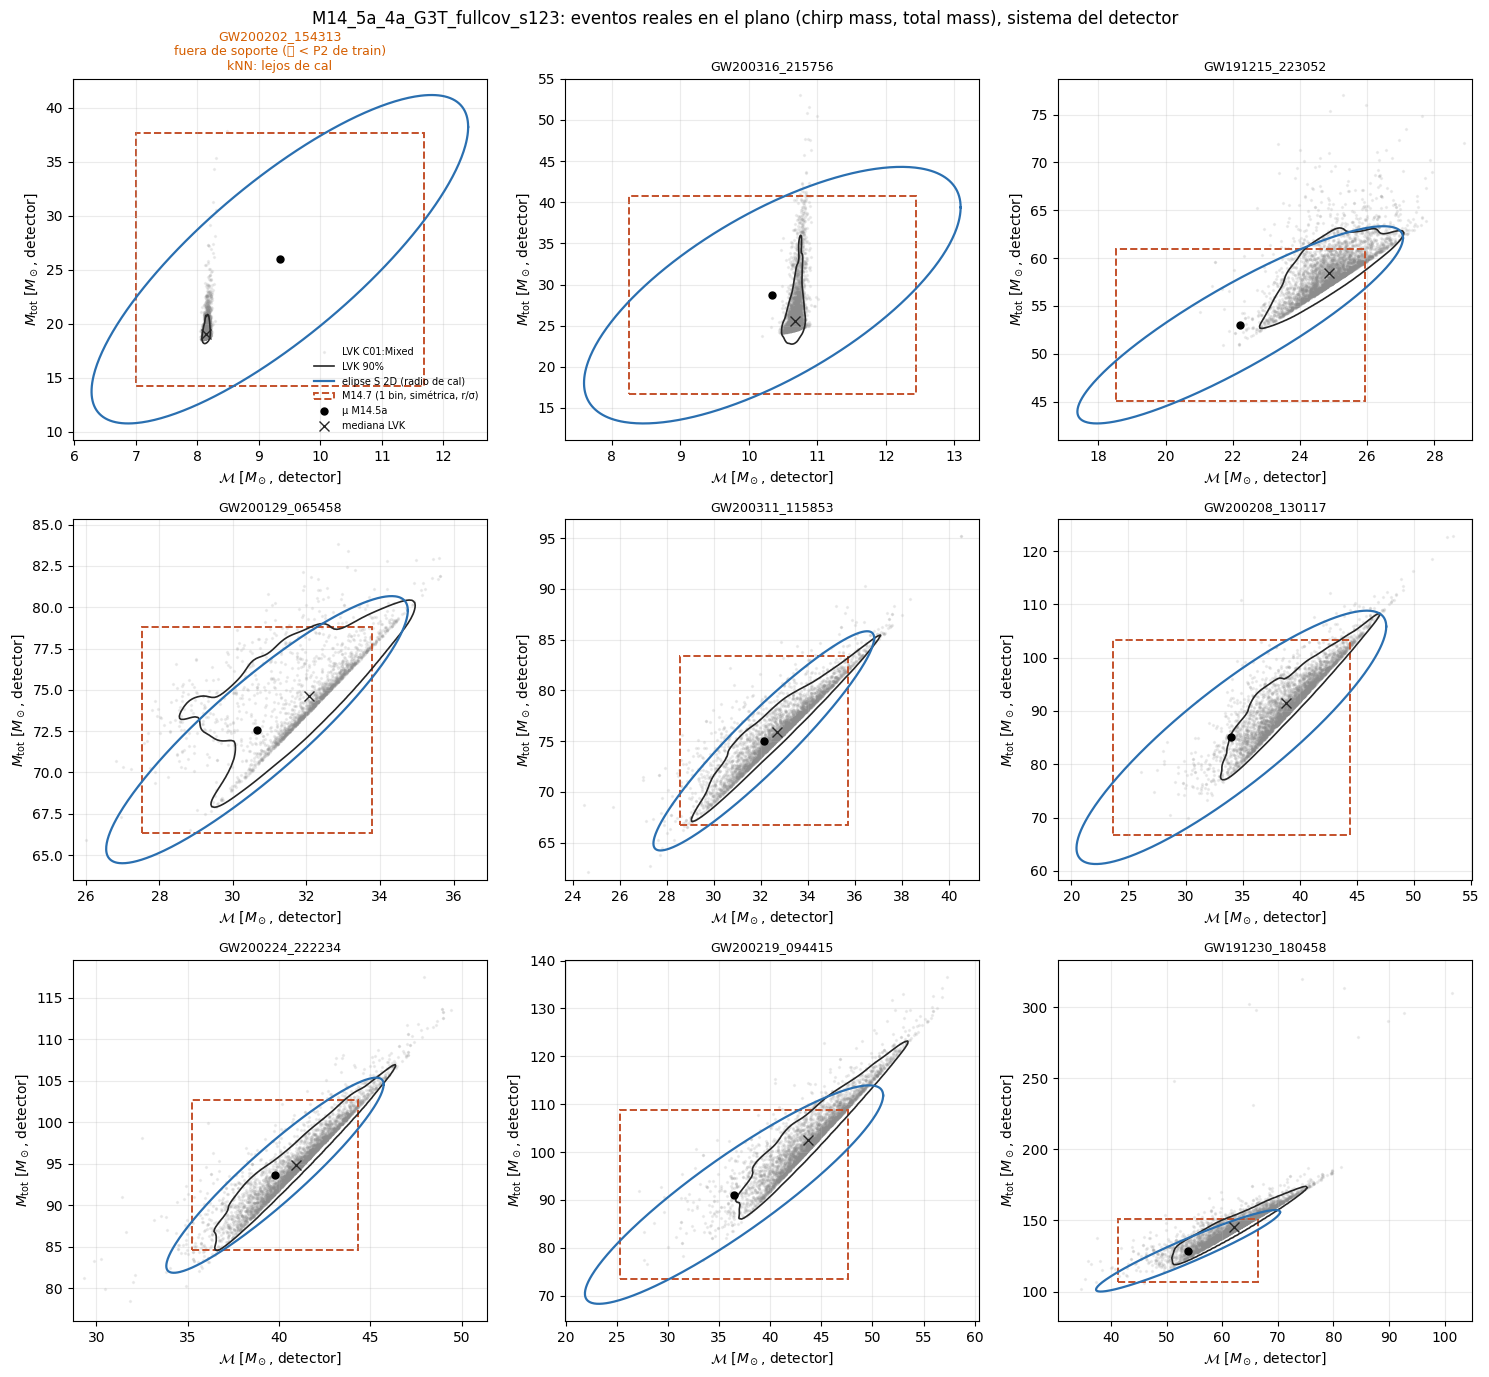

Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.


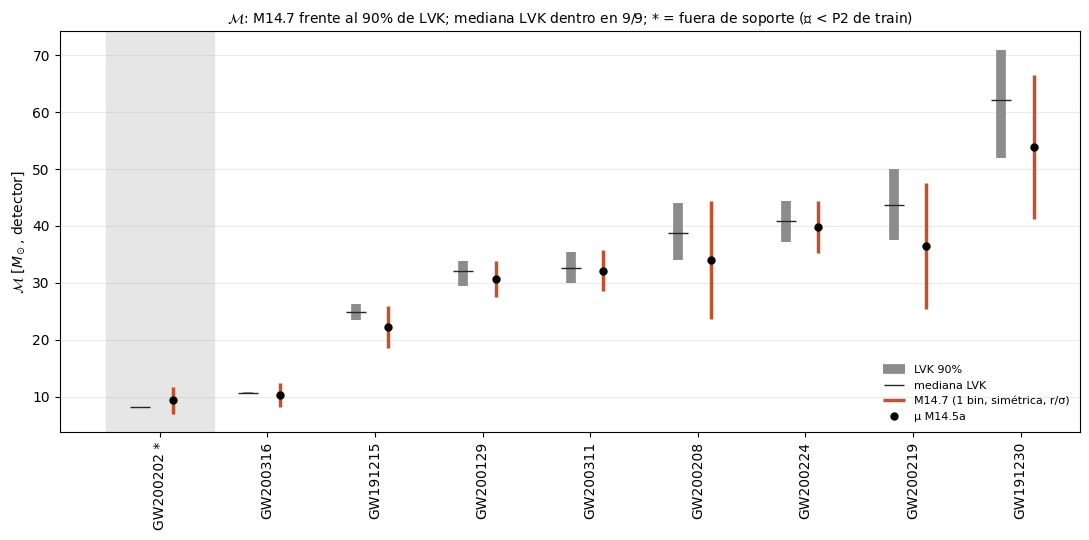

Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.


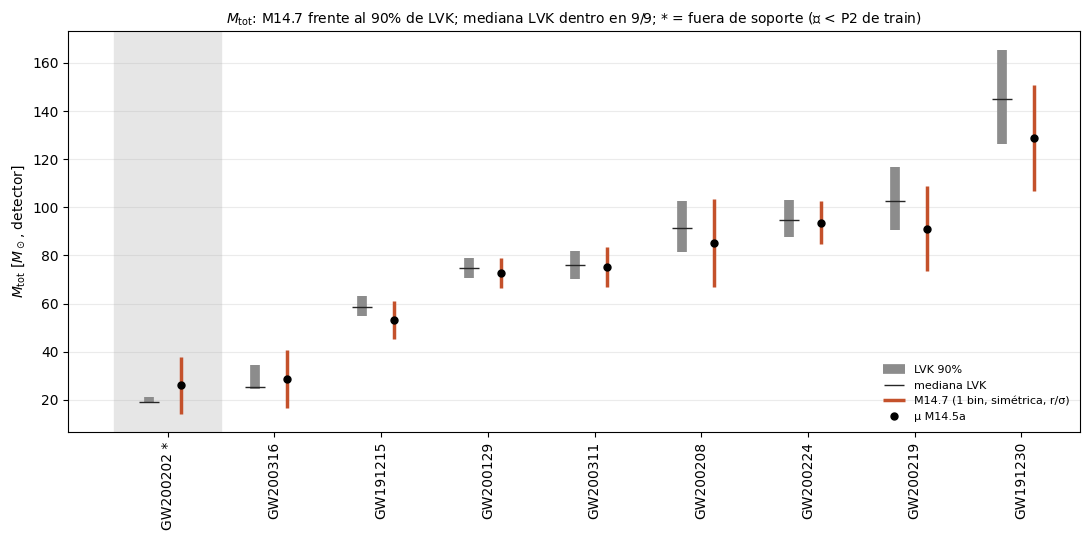

Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\U0001d4dc' [U+1d4dc], substituting with a dummy symbol.


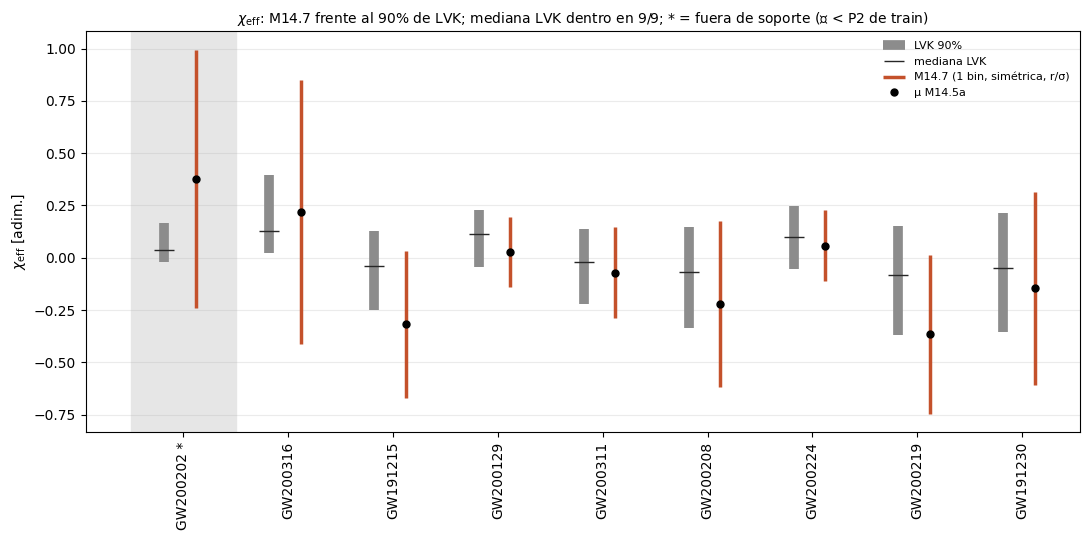

In [9]:
FIG_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = []

def save_figure(fig, name):
    for ext in ("png", "pdf"):
        path = FIG_DIR / f"{name}_{RUN_STAMP}.{ext}"
        with path.open("xb") as f:
            fig.savefig(f, format=ext, dpi=CONFIG["dpi"], bbox_inches="tight")
        FIGURES.append(str(path))
    plt.show()
    plt.close(fig)

def ellipse_points(mu2, cov2, radius, n=400):
    """Boundary r^T cov^-1 r = radius (radius is a squared Mahalanobis distance)."""
    t = np.linspace(0, 2 * np.pi, n)
    return mu2[None, :] + np.sqrt(radius) * (np.linalg.cholesky(cov2) @ np.vstack([np.cos(t), np.sin(t)])).T

def hpd_contour(ax, xy, level, rng, **kw):
    """Contour of the highest-density region with mass `level` of a Gaussian KDE of the samples."""
    sub = xy[rng.choice(len(xy), size=min(len(xy), CONFIG["kde_max"]), replace=False)]
    kde = gaussian_kde(sub.T)
    threshold = np.quantile(kde(sub.T), 1 - level)
    lo, hi = np.quantile(xy, [0.001, 0.999], axis=0)
    pad = 0.15 * (hi - lo)
    gx, gy = np.meshgrid(np.linspace(lo[0] - pad[0], hi[0] + pad[0], CONFIG["kde_grid"]),
                         np.linspace(lo[1] - pad[1], hi[1] + pad[1], CONFIG["kde_grid"]))
    dens = kde(np.vstack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
    ax.contour(gx, gy, dens, levels=[threshold], **kw)

rng_fig = np.random.default_rng(CONFIG["seed"])
mc_i, mt_i = LABELS.index("chirp_mass"), LABELS.index("total_mass")
lab, uni = CONFIG["labels"], CONFIG["units"]
fig, axes = plt.subplots(3, 3, figsize=CONFIG["grid_figsize"])
for ax, event in zip(axes.ravel(), event_order):
    i = EV_NAMES.index(event)
    xy = PE_SAMPLES[event][:, [mc_i, mt_i]]
    sc = xy[rng_fig.choice(len(xy), size=min(len(xy), CONFIG["max_scatter"]), replace=False)]
    ax.scatter(sc[:, 0], sc[:, 1], s=CONFIG["lvk"]["scatter_size"], color=CONFIG["lvk"]["color"],
               alpha=CONFIG["lvk"]["scatter_alpha"], rasterized=True, label=CONFIG["lvk"]["name"])
    hpd_contour(ax, xy, PE_LEVEL, rng_fig, colors=CONFIG["lvk"]["contour_color"], linewidths=1.2)
    ax.plot([], [], color=CONFIG["lvk"]["contour_color"], lw=1.2, label=f"LVK {PE_LEVEL:.0%}")
    ep = ellipse_points(MU_PHYS[i, [mc_i, mt_i]], COV_PHYS[i][np.ix_([mc_i, mt_i], [mc_i, mt_i])], RADIUS_S["2D"])
    ax.plot(ep[:, 0], ep[:, 1], color=CONFIG["ellipse"]["color"], lw=1.6, label=CONFIG["ellipse"]["name"])
    rc, rt = MAIN["chirp_mass"], MAIN["total_mass"]
    ax.add_patch(Rectangle((rc["lower"][i], rt["lower"][i]), rc["upper"][i] - rc["lower"][i],
                           rt["upper"][i] - rt["lower"][i], fill=False, ec=CONFIG["main"]["color"], lw=1.4,
                           ls="--", label=CONFIG["main"]["name"]))
    ax.plot(*MU_PHYS[i, [mc_i, mt_i]], "o", color=CONFIG["mu"]["color"], ms=5, label=CONFIG["mu"]["name"])
    ax.plot(*np.median(xy, axis=0), "x", color=CONFIG["lvk_median"]["color"], ms=7, label=CONFIG["lvk_median"]["name"])
    flag = KNN.set_index("event").loc[event, "knn_flag"]
    title = event + (f"\n{OUT_OF_SUPPORT[event]}" if event in OUT_OF_SUPPORT else "") + (f"\nkNN: {flag}" if flag else "")
    ax.set_title(title, fontsize=9, color="#D55E00" if event in OUT_OF_SUPPORT else "k")
    ax.set_xlabel(f"{lab['chirp_mass']} [{uni['chirp_mass']}]")
    ax.set_ylabel(f"{lab['total_mass']} [{uni['total_mass']}]")
    ax.grid(alpha=0.25)
axes.ravel()[0].legend(fontsize=7, frameon=False, loc="best")
fig.suptitle(f"{MODEL_TAG}: eventos reales en el plano (chirp mass, total mass), sistema del detector")
fig.tight_layout()
save_figure(fig, CONFIG["fig_names"]["grid"])

for l in LABELS:
    t = PER_LABEL[PER_LABEL.label == l].set_index("event").loc[event_order].reset_index()
    x = np.arange(len(t))
    fig, ax = plt.subplots(figsize=CONFIG["label_figsize"])
    ax.vlines(x - 0.18, t.lvk_pe_lower90, t.lvk_pe_upper90, color=CONFIG["lvk"]["color"], lw=7, label=f"LVK {PE_LEVEL:.0%}")
    ax.plot(x - 0.18, t.lvk_pe_median, "_", color=CONFIG["lvk_median"]["color"], ms=14, label=CONFIG["lvk_median"]["name"])
    ax.vlines(x + 0.12, t.main_lower, t.main_upper, color=CONFIG["main"]["color"], lw=2.5, label=CONFIG["main"]["name"])
    ax.plot(x + 0.12, t.mu, "o", color=CONFIG["mu"]["color"], ms=5, label=CONFIG["mu"]["name"])
    for k, event in enumerate(t.event):
        if event in OUT_OF_SUPPORT:
            ax.axvspan(k - 0.5, k + 0.5, color="0.9", hatch="//", zorder=0)
    ax.set_xticks(x)
    ax.set_xticklabels([e.split("_")[0] + (" *" if e in OUT_OF_SUPPORT else "") for e in t.event], rotation=90)
    ax.set_ylabel(f"{lab[l]} [{uni[l]}]")
    n_in = int(t.lvk_median_inside_main.sum())
    ax.set_title(f"{lab[l]}: M14.7 frente al {PE_LEVEL:.0%} de LVK; mediana LVK dentro en {n_in}/{len(t)}; "
                 f"* = {list(OUT_OF_SUPPORT.values())[0]}", fontsize=10)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8, frameon=False)
    fig.tight_layout()
    save_figure(fig, CONFIG["fig_names"]["per_label"].format(label=l))

## 9. Resumen JSON (modo `'x'`)

In [10]:
summary = dict(
    experiment="M14.5 real events", model_tag=MODEL_TAG, run_stamp_utc=RUN_STAMP, run_dir=str(RUN_DIR),
    created_utc=datetime.now(timezone.utc).isoformat(), descriptive=True,
    data_roles=dict(cal="M14.7 calibrators (stored, not refitted); inherited M11 v1/v2 quantiles and S radii (reconstructed, as M14.5)",
                    val="reproduction gates only (M14.7 configuration, inherited Mondrian)",
                    test="reference distribution of the kNN distance only", train="P2 of chirp_mass (support flag)",
                    real_events="descriptive only, n = 9; nothing fitted or selected"),
    inputs=dict(events_x=input_entry(EVENTS_X), events_pred=input_entry(EVENTS_PRED),
                pred={s: input_entry(p) for s, p in PRED_PATHS.items()}, checkpoint=dict(path=str(CHECKPOINT), sha256=CHECKPOINT_SHA256),
                m14_5_summary=input_entry(M14_5_SUMMARY), m14_7_bundle=input_entry(M14_7_BUNDLE),
                m14_7_selection=input_entry(M14_7_SELECTION), m14_7_summary=input_entry(M14_7_SUMMARY), m13_13_real_events_json=input_entry(M13_13_REAL_JSON),
                m13_13_amendment6_json=input_entry(M13_13_MONDRIAN_JSON), m13_7_summary=input_entry(M13_7_SUMMARY),
                m11_selection=input_entry(M11_SELECTION), m11_bundle_manifest=input_entry(M11_BUNDLE_MANIFEST),
                split=str(SPLIT_PATH), label_stats=str(LABEL_STATS_PATH), g3_h5=str(G3_H5)),
    npz_provenance=NPZ_PROVENANCE, events_x_metadata=EV_META, events_pred_metadata=PRED_META,
    reused_sources=reused_sources, checks=dict(passed=True, n=len(CHECKS), names=CHECKS),
    events=EV_NAMES, event_order_by_lvk_chirp=event_order, gps=EV_GPS, out_of_support=OUT_OF_SUPPORT,
    main_intervals=dict(source="M14.7", run=M14_7_RUN_REL, config=M14_7_CONFIG,
                        offsets_standardized_r_over_sigma={l: q.tolist() for l, q in M14_7_Q.items()},
                        application="mu + [q_lo, q_hi] sigma, sigma = sqrt(diag Sigma); physical = value * y_std + y_mean",
                        val_gate=records(M14_7_VAL), tol=M14_7_VAL_TOL),
    mondrian_inherited_m11_reference=dict(role="descriptive reference and kNN difficulty model only", hyperparameters=HP, primary_policy=PRIMARY_POLICY, systems=ours_systems,
                  bundle=dict(path=str(BUNDLE_PATH), sha256=BUNDLE_SHA256),
                  reconstruction_gate_val=records(RECON), cov_atol=MONDRIAN_VAL_COV_ATOL, width_rtol=MONDRIAN_VAL_WIDTH_RTOL),
    ellipsoid_S=dict(level=LEVEL, k_rank=K_RANK, n_cal=n_cal, radius=RADIUS_S, amendment_2_decision=A2_DECISION),
    lvk_posterior=dict(source="Zenodo 8177023 (GWTC-3 PE, v2)", variant=PE_VARIANT, group=PE_GROUP, level=PE_LEVEL,
                       frame="detector", files=pe_info),
    per_event_label=records(PER_LABEL), ellipsoid_per_event=records(ELLIPSE), counts=records(COUNTS), counts_S=COUNTS_S,
    reference_m11_per_event_label=records(REFERENCE_M11), reference_m11_counts=records(COUNTS_REF_M11),
    knn=dict(test_distribution=KNN_TEST, far_quantile=KNN_FAR_QUANTILE, per_event=records(KNN)),
    support=dict(quantile=SUPPORT_QUANTILE, p2_chirp_mass_train=P2_CHIRP_TRAIN, premise_holds=SUPPORT_PREMISE),
    comparison_m13_13_amendment6=dict(model=M13_13_TAG, rows=records(COMPARE), summary=records(COMPARE_SUMMARY)),
    figures=FIGURES, config=CONFIG,
    versions=dict(python=sys.version, numpy=np.__version__, pandas=pd.__version__))
with JSON_PATH.open("x", encoding="utf-8") as f:
    json.dump(to_json(summary), f, indent=2, ensure_ascii=False, default=str)
print("Summary:", JSON_PATH)

Summary: /data/vserrano/cbc_pe_data/results/M13_3/M14_5/real_events/M14_5_real_events_M14_5a_4a_G3T_fullcov_s123_20261112T170136Z.json


## Lectura (12-11-2026)

**Descriptivo (n = 9, una semilla, posteriores LVK C01:Mixed en el sistema del detector).**

### Verificado
- **Gates:** 88 comprobaciones; inferencia de eventos en la VM con val-check exacto (|Δμ| = |Δcov| = 0 en 64 filas); configuración de M14.7 (1 bin, r/σ, q = 1,601 / 1,615 / 1,625) reproduce su cobertura y anchura en val.
- **Intervalos M14.7 frente a LVK:** mediana LVK dentro en 9/9 para 𝓜, M_tot y χ_eff (modelo anterior 4a-G3T con Mondrian heredado: 8/9, 7/9, 7/9). Anchura / 90 % LVK (mediana) 1,77 / 1,50 / 1,62. |Residuo| mediano frente a la mediana LVK: 2,61 → 1,41 (𝓜), 5,68 → 5,39 (M_tot), 0,134 → 0,096 (χ_eff).
- **Elipsoide conformal con Σ aprendida:** mediana LVK dentro en 9/9 (3D y 2D); fracción mediana de muestras LVK dentro de la elipse 2D 0,95 (mínimo 0,76 en GW191230).
- **Soporte:** GW200202 fuera de soporte (𝓜 bajo el P2 de train; kNN en P99,6 de test), con σ grande (χ_eff σ = 0,38). Resto de eventos con kNN ≤ P97.

### Interpretación (hipótesis)
- En masa intermedia y alta, la elipse aprendida sigue la dirección de degeneración de la posterior de LVK: la estructura aprendida en simulación se transfiere a datos reales.
- Los intervalos son algo más anchos que los del modelo anterior en estos eventos (mediana +16 / +24 / +31 %), coherente con que el intervalo antiguo infracubría a SNR bajo (no medido aquí).
- Sesgo a la baja en masa alta (GW191230 𝓜 −8,2; GW200219 −7,3): regresión a la media del estimador cerca del borde del prior, como en M13.13.
- En baja masa la PE completa es 18–48× más precisa en 𝓜 (información de fase).

### No se puede concluir
- La cobertura en datos reales (n = 9; la mediana LVK no es el valor verdadero; priors distintos).
- La transferencia a eventos fuera del soporte de simulación.